# IND320-1 26H Data til beslutning
**Student:** Lovisa Nguyen  
[GitHub](https://github.com/myelovis/reservoir_streamlit_app) · [Streamlit app](https://reservoir-app-datatodecision-v2026.streamlit.app/) · [Screencast](https://www.dropbox.com/scl/fi/o32gvoka0vsb412lqkt86/dtbpart4_edited.mp4?rlkey=2rmcig3zgjxxho6o4olo12p4w&st=gdxxqvq7&dl=0)

# Project work, part 4 - Machine Learning


## Contents
1. Setup and install
2. Norwegian Bank (NB) API for EURO - USD Exchange function
3. Timezone between Megasinstatistikk, ENTSO-E, OpenMeteo and NB
4. Reservoir, weather and weekly alignment
5. Streamlit app - Refactoring
6. WOrk log
7. AI Usage

## 1. Setup and install

In [8]:
#%pip install -r requirement.txt

In [9]:
from pathlib import Path
from io import StringIO
from time import perf_counter
import json
import math
import hashlib
import platform
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display, Markdown, HTML
from tqdm.auto import tqdm
from river import linear_model, optim, preprocessing

WORK = Path("workca4/reservoir_project")
WORK.mkdir(parents=True, exist_ok=True)
session = requests_cache.CachedSession(str(WORK / "http"), expire_after=86400)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
)))

COLOURS = ["#0F766E", "#2563EB", "#D97706", "#9333EA", "#DC2626"]
pio.templates["reservoir"] = go.layout.Template(
    layout=dict(template="plotly_white", colorway=COLOURS,
                paper_bgcolor="#F8FAFC", plot_bgcolor="#F8FAFC",
                font=dict(family="Arial", color="#16324F"),
                hovermode="x unified", margin=dict(l=55, r=30, t=65, b=50))
)
pio.templates.default = "reservoir"
pio.renderers.default = "plotly_mimetype+notebook_connected"

def get_response(url, params=None):
    """Bounded retries; useful messages; never invent replacement observations."""
    try:
        response = session.get(url, params=params, timeout=(15, 120))
        response.raise_for_status()
        return response
    except requests.RequestException as exc:
        raise RuntimeError(
            f"Data connection failed ({url.split('/')[2]}). "
            "Check internet/service status and retry. Existing successful cache entries remain available."
        ) from exc

packages = ["pandas", "numpy", "plotly", "river", "scipy", "scikit-learn",
            "statsmodels", "requests", "requests-cache", "geopandas"]
versions = {p: metadata.version(p) for p in packages}
display(pd.Series({"Python": platform.python_version(), **versions}, name="Executed versions"))

Python            3.11.17
pandas              2.3.3
numpy              1.26.4
plotly              7.1.0
river              0.23.0
scipy              1.17.1
scikit-learn        1.9.1
statsmodels        0.15.0
requests           2.34.2
requests-cache      1.3.3
geopandas           1.0.1
Name: Executed versions, dtype: object

## 2. Norwegian Bank (NB) API for EURO - USD Exchange function

The function will look for the most current recorded exchange rate and return it. So, for example, today is Sunday, the previous record will be from Friday.

In [10]:
def latest_eur_usd_exchane_rate():
    response = requests.get(
        "https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP",
        params={"format": "csv", "lastNObservations": 1, "locale": "en"},
        timeout=30,
    )
    response.raise_for_status()

    rates = pd.read_csv(StringIO(response.text), sep=";").pivot(
        index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE"
    )
    return (rates["EUR"] / rates["USD"]).round(2).rename("EUR : USD rate")


display(latest_eur_usd_exchane_rate())

TIME_PERIOD
2026-11-16    1.1
Name: EUR : USD rate, dtype: float64

## 3. Timezone between Megasinstatistikk, ENTSO-E, OpenMeteo and NB


In [11]:
from getpass import getpass
from io import StringIO


def timezone_examples(token=None):
    token = token or getpass("ENTSO-E API token: ").strip()

    urls = {
        "Magasinstatistikk": "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligDataSisteUke",
        "Open-Meteo": "https://api.open-meteo.com/v1/forecast",
        "Norges Bank": "https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP",
        "ENTSO-E": "https://web-api.tp.entsoe.eu/api",
    }
    params = {
        "Magasinstatistikk": {},
        "Open-Meteo": dict(
            latitude=63.43, longitude=10.40,
            hourly="temperature_2m", timezone="GMT", forecast_days=1,
        ),
        "Norges Bank": dict(format="csv", lastNObservations=2, locale="en"),
        "ENTSO-E": dict(
            securityToken=token, documentType="A44",
            in_Domain="10YNO-3--------J", out_Domain="10YNO-3--------J",
            periodStart="202601010000", periodEnd="202601020000",
        ),
    }

    for name, url in urls.items():
        print(f"\n{name}")
        if name == "ENTSO-E" and not token:
            print("Skipped: API token required.")
            continue
        try:
            r = requests.get(url, params=params[name], timeout=30)
            r.raise_for_status()

            if name == "ENTSO-E":
                print(r.text[:800])
            elif name == "Norges Bank":
                print(pd.read_csv(StringIO(r.text), sep=";")[
                    ["TIME_PERIOD", "BASE_CUR", "OBS_VALUE"]
                ].to_string(index=False))
            else:
                data = r.json()
                print(pd.DataFrame(
                    data["hourly"] if name == "Open-Meteo" else data
                ).head(2).to_string(index=False))

        except (requests.RequestException, ValueError, KeyError):
            print("Request failed: check connection, parameters or token.")

    print("\nTimezones")
    print(pd.DataFrame({
        "API": list(urls),
        "Time convention": [
            "Weekly date label; Local timezone",
            "GMT / UTC (explicitly requested)",
            "Business date; CET timezone",
            "UTC timestamps",
        ],
    }).to_string(index=False))


timezone_examples()

ENTSO-E API token:  ········



Magasinstatistikk
   dato_Id omrType  omrnr  iso_aar  iso_uke  fyllingsgrad  kapasitet_TWh  fylling_TWh neste_Publiseringsdato  fyllingsgrad_forrige_uke  endring_fyllingsgrad
2026-11-08      EL      4     2026       45      0.920749      21.079208    19.408653    2026-11-18T13:00:00                  0.905179              0.015570
2026-11-08      EL      3     2026       45      0.718765       8.920932     6.412049    2026-11-18T13:00:00                  0.720138             -0.001373

Open-Meteo
            time  temperature_2m
2026-11-17T00:00             1.6
2026-11-17T01:00             1.5

Norges Bank
TIME_PERIOD BASE_CUR  OBS_VALUE
 2026-11-13      USD     9.5634
 2026-11-16      USD     9.6005
 2026-11-13      EUR    10.5695
 2026-11-16      EUR    10.5740

ENTSO-E
<?xml version="1.0" encoding="utf-8"?>
  <Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:3">
    <mRID>f3f0521a6f0d4c0ba968d73bbaa3ac86</mRID>
    <revisionNumber>1</revisionNu

Explorations:

* Megasinstatistikk uses weekly date labels with timezone of Norway because it serves the database for local society.

* ENTSO-E uses UTC timestamps with the timezone of Europe/Oslo for local aggregation.

* Open-Meteo is integrated with GMT/UTC with possibility for data aggregating of Norwegian daily or weekly periods when the mode Europe/Oslo is turn on.

* Norges Bank offers business dates and its records are updated around 16:00 CET timezone.  

## 4 · SARIMAX Forcasting with Magasinstatistikk API

In this task we will fetch data from Magasinstatistikk with the time_resolution of 7 days or one-week. This will reduce the demand of computation in comparision to the hourly or daily and still keep seasonal detail more that that of monthly option.

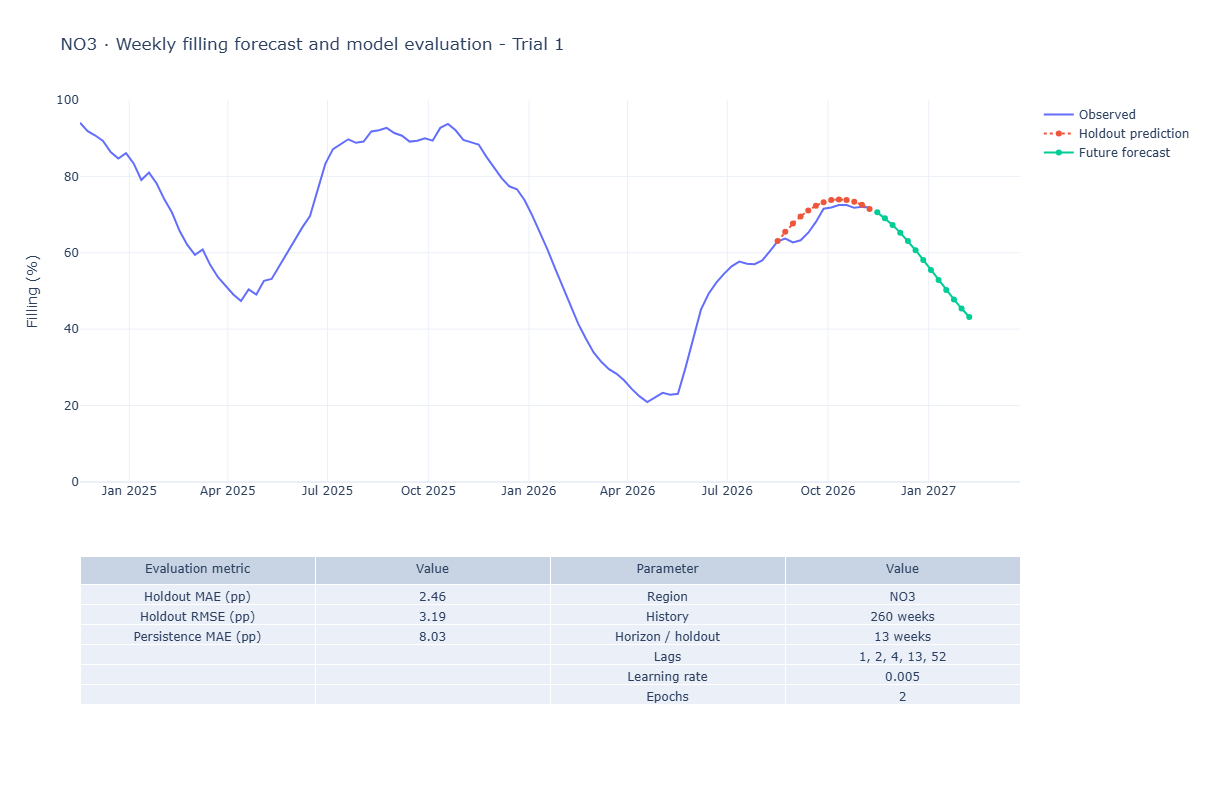

In [12]:

def forecast_filling(region=3,
                     history=260,  # 260 weekly observations ≈ 5 years
                     horizon=13,
                     lags=(1, 2, 4, 13, 52),
                     learning_rate=0.005, epochs=2, end=None):

    # Fetch data and select one electricity region.
    response = requests.get(
        "https://biapi.nve.no/magasinstatistikk/api/"
        "Magasinstatistikk/HentOffentligData",
        timeout=60,
    )
    response.raise_for_status()
    data = pd.DataFrame(response.json())
    data = data.loc[
        data["omrType"].eq("EL") & data["omrnr"].eq(region)
    ].copy()
    data["date"] = pd.to_datetime(data["dato_Id"])

    filling = (
        data.set_index("date")["fyllingsgrad"]
        .astype(float).mul(100).sort_index()
    )
    if end is not None:
        filling = filling.loc[:end]

    # Validate inputs.
    if not lags or any(not isinstance(k, int) or k < 1 for k in lags):
        raise ValueError("Lags must be positive integers.")
    if not isinstance(horizon, int) or not 1 <= horizon <= 52:
        raise ValueError("Horizon must be an integer from 1 to 52.")
    if not isinstance(epochs, int) or epochs < 1 or learning_rate <= 0:
        raise ValueError("Use positive epochs and learning rate.")
    if (not isinstance(history, int)
            or history < max(lags) + 52 + horizon
            or len(filling) < history):
        raise ValueError(
            "Need history >= max(lags) + 52 + horizon, "
            "and enough available observations."
        )

    filling = filling.iloc[-history:]

    if (not filling.index.is_unique
            or not filling.index.to_series().diff().dropna()
                          .eq(pd.Timedelta(days=7)).all()
            or not filling.between(0, 100).all()):
        raise ValueError("Provide complete, unique weekly filling values in [0,100].")

    def features(values, date):
        angle = 2 * np.pi * date.dayofyear / 365.2425
        return {
            **{f"lag_{lag}": values[-lag] / 100 for lag in lags},
            "sin": np.sin(angle),
            "cos": np.cos(angle),
        }

    def fit_predict(series, steps):
        model = preprocessing.StandardScaler() | linear_model.LinearRegression(
            optimizer=optim.SGD(learning_rate),
            intercept_lr=learning_rate,
            l2=0.001,
        )
        values = series.to_list()

        for _ in range(epochs):
            for i in range(max(lags), len(values)):
                x = features(values[:i], series.index[i])
                change = (values[i] - values[i - 1]) / 100
                model.learn_one(x, change)

        dates = pd.date_range(
            series.index[-1] + pd.Timedelta(days=7),
            periods=steps, freq="7D",
        )
        predictions = []

        for date in dates:
            change = model.predict_one(features(values, date))
            prediction = float(np.clip(values[-1] + 100 * change, 0, 100))
            predictions.append(prediction)
            values.append(prediction)

        return pd.Series(predictions, index=dates)

    # Test on the last 'horizon' observed weeks, without training on them.
    train = filling.iloc[:-horizon]
    actual = filling.iloc[-horizon:]
    test_prediction = fit_predict(train, horizon)

    errors = actual.to_numpy() - test_prediction.to_numpy()
    metrics = {
        "Holdout MAE (pp)": np.abs(errors).mean(),
        "Holdout RMSE (pp)": np.sqrt(np.mean(errors**2)),
        "Persistence MAE (pp)": np.abs(actual - train.iloc[-1]).mean(),
    }

    # Refit using all selected observations for the future forecast.
    forecast = fit_predict(filling, horizon).rename("Forecast (%)")

    return filling, forecast, test_prediction, metrics


observed, forecast, test_prediction, metrics = forecast_filling(
    region=3, history=260, horizon=13,
    lags=(1, 2, 4, 13, 52), learning_rate=0.005, epochs=2,
)

# Plot forecasts and a table of metrics / parameters.
fig = make_subplots(
    rows=2, cols=1,
    specs=[[{"type": "xy"}], [{"type": "table"}]],
    row_heights=[0.7, 0.3],
    vertical_spacing=0.12,
)

fig.add_trace(go.Scatter(
    x=observed.index[-104:], y=observed.iloc[-104:],
    name="Observed",
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=test_prediction.index, y=test_prediction,
    name="Holdout prediction", line=dict(dash="dot"),
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=forecast.index, y=forecast,
    name="Future forecast", mode="lines+markers",
), row=1, col=1)

fig.add_trace(go.Table(
    header=dict(values=["Evaluation metric", "Value", "Parameter", "Value"]),
    cells=dict(values=[
        list(metrics) + ["", "", ""],
        [f"{value:.2f}" for value in metrics.values()] + ["", "", ""],
        ["Region", "History", "Horizon / holdout", "Lags", "Learning rate", "Epochs"],
        ["NO3", "260 weeks", "13 weeks", "1, 2, 4, 13, 52", "0.005", "2"],
    ]),
), row=2, col=1)

fig.update_layout(
    title="NO3 · Weekly filling forecast and model evaluation - Trial 1",
    template="plotly_white",
    height=800,
)
fig.update_yaxes(title_text="Filling (%)", range=[0, 100], row=1, col=1)
fig.show()

* Trial 1: The plot shows clear about the year-changing point, with 13 weeks as houtout-period. The model follows nicely to the observed values, with a little bit higher in absolute value but still in the same pattern of the curve. For the 13 forcasted weeks, the data points go down well in tune with the pattern ofbserved in previous cycle. With history = 260 weeks, the model gets redundant amount of data to forcast the pattern while learning slowly with learning_rate = 0.0005. MAE of 2.46 is recorded for holdout, with RMSE 3.19. The model beats the naive guessing, with Holdout MAE smaller than Persistence MAE. 

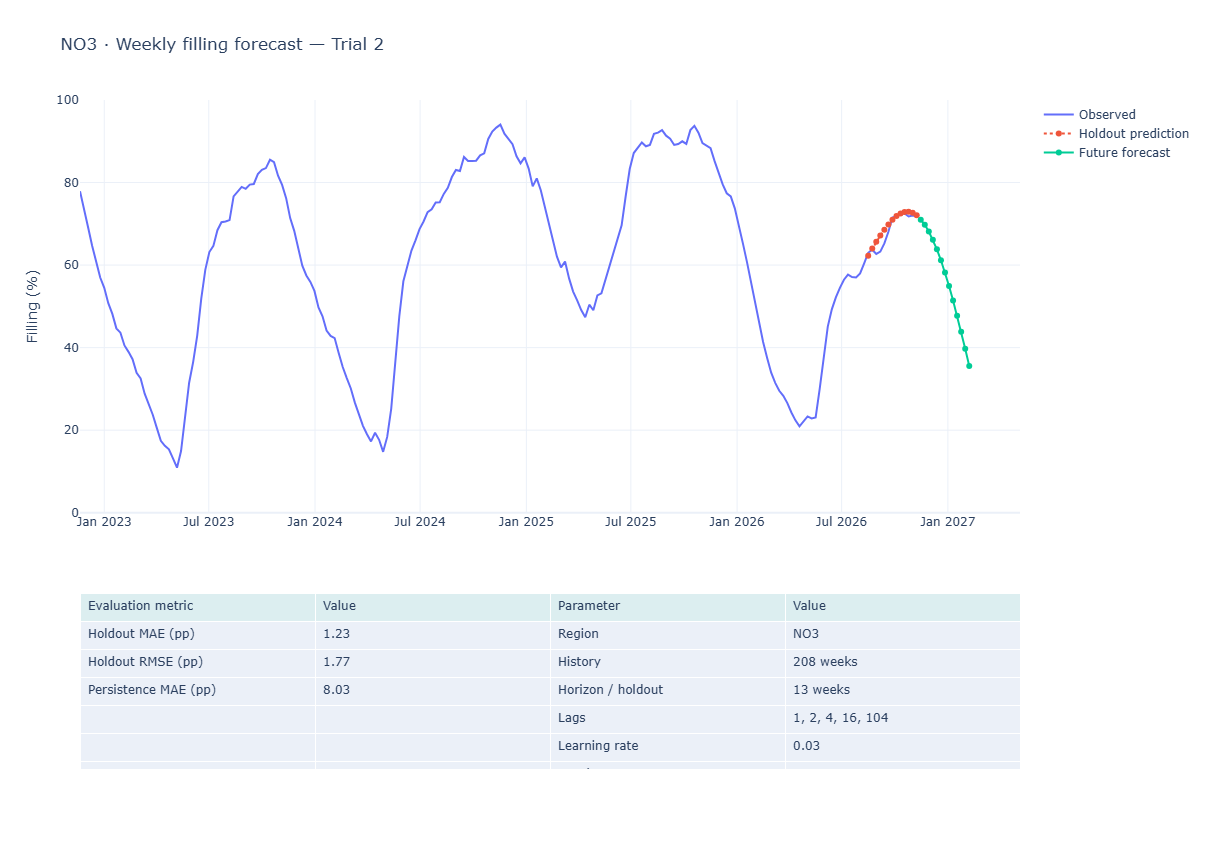

In [13]:
settings = {
    "region": 3,
    "history": 208,
    "horizon": 13,
    "lags": (1, 2, 4, 16, 104), 
    "learning_rate": 0.03, # x60 times fasters
    "epochs": 2,
}

observed, forecast, test_prediction, metrics = forecast_filling(**settings)

fig = make_subplots(
    rows=2, cols=1,
    specs=[[{"type": "xy"}], [{"type": "table"}]],
    row_heights=[0.7, 0.3],
    vertical_spacing=0.12,
)

fig.add_trace(go.Scatter(
    x=observed.index, y=observed,
    name="Observed",
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=test_prediction.index, y=test_prediction,
    name="Holdout prediction", line=dict(dash="dot"),
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=forecast.index, y=forecast,
    name="Future forecast", mode="lines+markers",
), row=1, col=1)

parameter_values = [
    f"NO{settings['region']}",
    f"{settings['history']} weeks",
    f"{settings['horizon']} weeks",
    ", ".join(map(str, settings["lags"])),
    str(settings["learning_rate"]),
    str(settings["epochs"]),
]

fig.add_trace(go.Table(
    header=dict(
        values=["Evaluation metric", "Value", "Parameter", "Value"],
        fill_color="#DCEEF0",
        align="left",
    ),
    cells=dict(
        values=[
            list(metrics) + [""] * 3,
            [f"{value:.2f}" for value in metrics.values()] + [""] * 3,
            ["Region", "History", "Horizon / holdout",
             "Lags", "Learning rate", "Epochs"],
            parameter_values,
        ],
        align="left",
        height=28,
    ),
), row=2, col=1)

fig.update_layout(
    title=f"NO{settings['region']} · Weekly filling forecast — Trial 2",
    template="plotly_white",
    height=850,
)
fig.update_yaxes(
    title_text="Filling (%)", range=[0, 100], row=1, col=1,
)
fig.show()

* Trial 2: For second trial, the model forcasting values (in holdout period) are more asymptotic to the observed values and the horizon values are going down faster than in Trial 1. The model learns much faster with a learning_rate of 60 times faster and it yields smaller RMSE in holdout. The lag of 52 week is removed with replacement of 104 and only 208 weeks are used as history. Holdout MAE is only 1.23 which is half in value in comparision with the previous trial. The model of Trial 2 beats the Naive guessing more better than the model from Trail 1. 

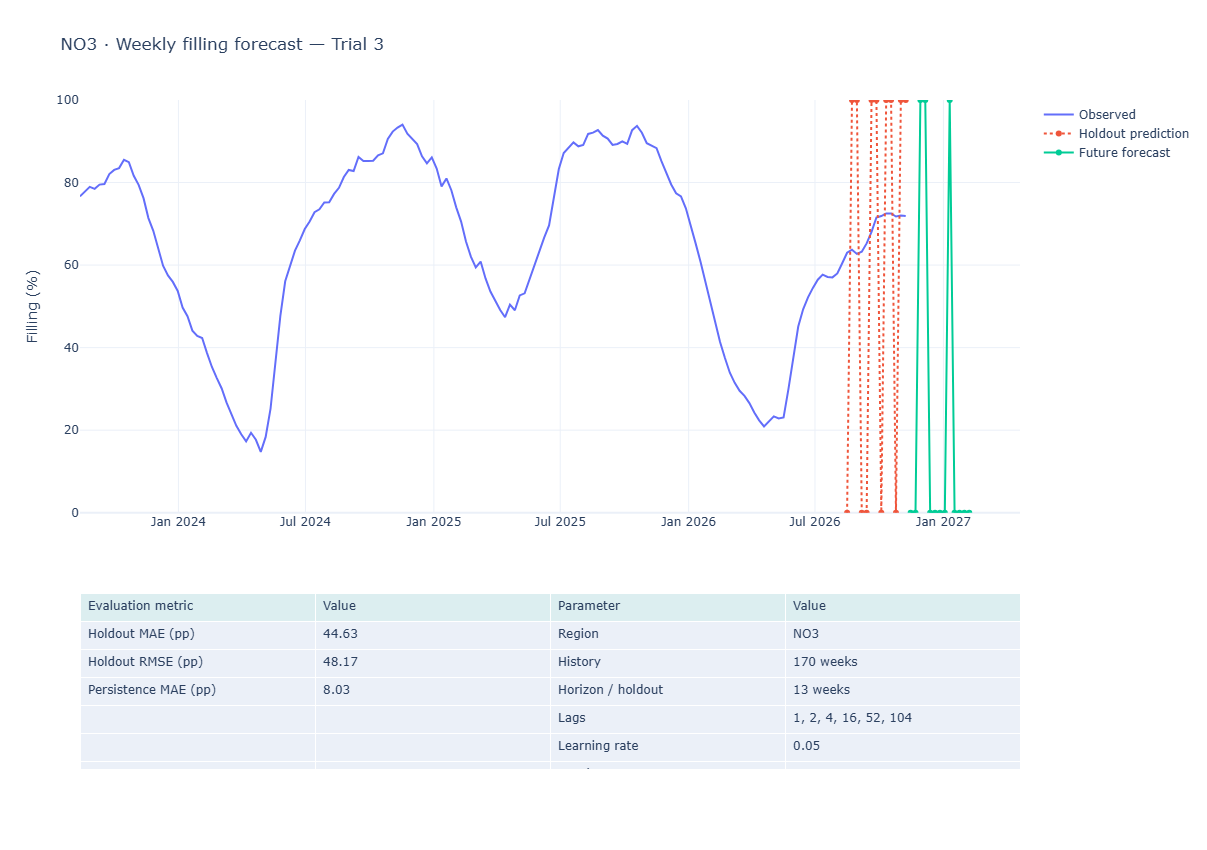

In [14]:
settings = {
    "region": 3,
    "history": 104 + 52 + 13 + 1, # ValueError: Need history >= max(lags) + 52 + horizon, and enough available observations.
    "horizon": 13,
    "lags": (1, 2, 4, 16, 52, 104), 
    "learning_rate": 0.05, # x10 times fasters than Trial 1
    "epochs": 2,
}

observed, forecast, test_prediction, metrics = forecast_filling(**settings)

fig = make_subplots(
    rows=2, cols=1,
    specs=[[{"type": "xy"}], [{"type": "table"}]],
    row_heights=[0.7, 0.3],
    vertical_spacing=0.12,
)

fig.add_trace(go.Scatter(
    x=observed.index, y=observed,
    name="Observed",
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=test_prediction.index, y=test_prediction,
    name="Holdout prediction", line=dict(dash="dot"),
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=forecast.index, y=forecast,
    name="Future forecast", mode="lines+markers",
), row=1, col=1)

parameter_values = [
    f"NO{settings['region']}",
    f"{settings['history']} weeks",
    f"{settings['horizon']} weeks",
    ", ".join(map(str, settings["lags"])),
    str(settings["learning_rate"]),
    str(settings["epochs"]),
]

fig.add_trace(go.Table(
    header=dict(
        values=["Evaluation metric", "Value", "Parameter", "Value"],
        fill_color="#DCEEF0",
        align="left",
    ),
    cells=dict(
        values=[
            list(metrics) + [""] * 3,
            [f"{value:.2f}" for value in metrics.values()] + [""] * 3,
            ["Region", "History", "Horizon / holdout",
             "Lags", "Learning rate", "Epochs"],
            parameter_values,
        ],
        align="left",
        height=28,
    ),
), row=2, col=1)

fig.update_layout(
    title=f"NO{settings['region']} · Weekly filling forecast — Trial 3",
    template="plotly_white",
    height=850,
)
fig.update_yaxes(
    title_text="Filling (%)", range=[0, 100], row=1, col=1,
)
fig.show()

* Trial 3: With the provided history of only 170 weeks and equipped for good value of the lag 52 (full one year period), the model of Trial 3 gets the worse Holdout MAE which is far more bigger than 8.03, nearly 50.5 times bigger in comparision with Persistence MAE. This tells how important it is to choose the right values for history- , lags- , and learning_rate parameters.

* By looking at Trial 1 and Trial 3, just simply increasing the history from 170 to 208 weeks and reducing the learning rate from 0.05 to 0.03 are enough helpful to reduce the Holdout MAE from 44.63 to ultimate good of 1.23. 

## 5. Streamlit app - Refactoring Sketch

Drawn with https://app.diagrams.net/
Color and visual effects will be styled-randomly in creating the app later.

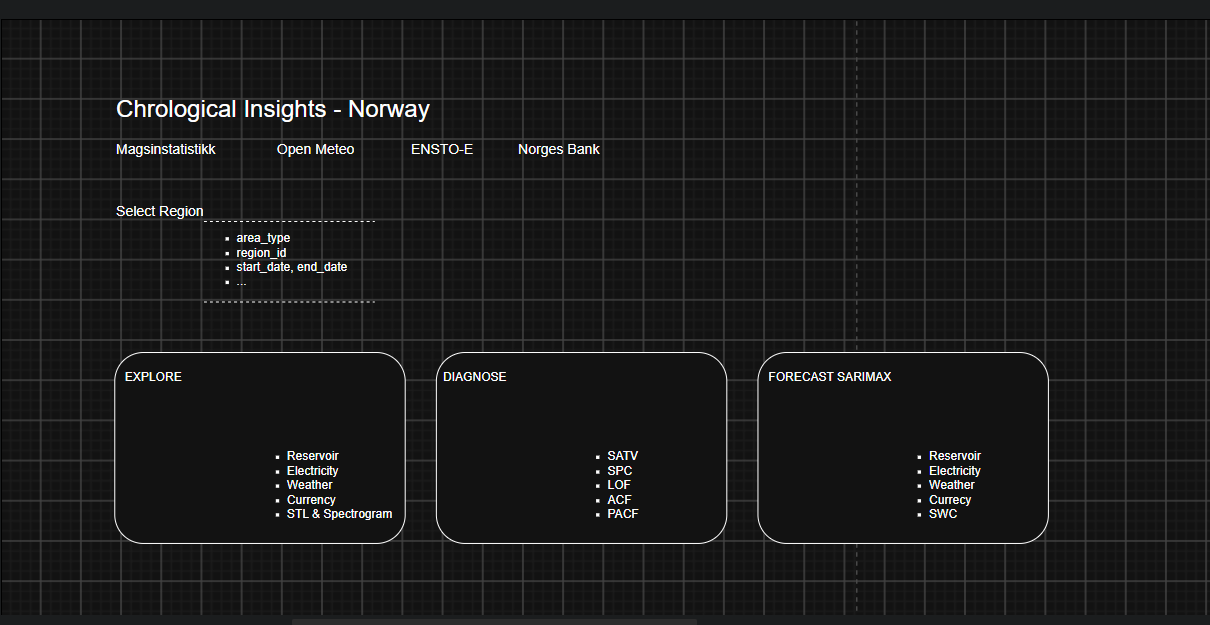

## 6. Work log 

For the Part 4 Jupyter notebook, firstly I built a function which fetch the Norwegian (Norges) Bank API for EURO - USD exchange rate data and then print the rate out. Using the .pivot() enables the reshaping of a long format of orignal stacked rows to side-by-side columns. 

Secondly, I fetch and download data from our four main data souces, of: Magasinstatistikk, ENTSO-E, Open Meteo and Norges Bank, to look for their timezone data from their timestamps. The functione printes out short examples which are easy to check and compare to each API. I learnt that the date lables alone should not treated as UTC timestamps.  

Thridly, for forecasting, via the Magasinstatistikk API, reservoir filling data for a single region of NO3 war retrieved and downloaded. I applied time resolution of 7 days or one-week time length in order to keep the computing time small and yet still keep enough data patterns, which might be loosen in case of longer one. Luckily we don't need geographic sample points because the main task is forecasting with the reservior filling-only model.

River framework is utilized with a lag-based machine learning function, with easy-tuning ability for parameters (training history, forecast horizon, lags, learning rate and epoch numbers). The it plots an  interactive chart showing observed filling curve, holdout forecasting points and future forecasting ones, with an attached table of parameters-tuning and erro measures. I tested different tuning complexes, of which results tell me how sensitive a model can be in coping with changing of one or multiple parameter at a time. Looking at the forecasting plots, one can easily tell how nicely a SARIMAM model can work with its favourite right-tuned parameters. 

Fourthly, I draw the Streamlit app - Refactoring from sketch. Through the process of making the sketch, I reorganised the data, the input, the output and groupped data into three main elevations: Exploration, Diagnose and Forecasting. The newly created framework of the app pages will provide easy-to-locate and friendly-user-experience to visitors. The plots will be interactive, subtly-catchy in same color tones. 

Fifthly, the Streamlit app is updated with GeoJSON-based map, with UX-friendly features such as different colouring for different Prive area, Water area or Weather property. There are full of different interactive elements. Then, later weather property selection is applied to SAVT plots with the weather as default choice. Selectable lag and window lenth from Sliding Window Correlation are upgraded into Plotly graphics. 

Sixthly, SARIMAX Machine Learning model is applied to the water magazine filling with parameter-tunable feature, which anables the ability to allow them to be selectable and adjustable where the user can choose timeframe for the training data as well the forecast horizon. Results are plotted with plotly animation. 

Seventhly, for the bonus task, I choose all the tasks offered from the assignment as an opportunity to learn and figure out on expanding my skill as well as to make the Streamlit app to be full of 5-stars evaluation from users. Each bonus task of: Waiting time (Progress bar), Error handling (System Self-healing), Elevation Map from Opem-Meteo API and SARIMAX Confidence intervals is implemented step by step.


## 7. AI Usage

Gemini and Codex are my assistants in doing the task, from re-explorating the assignment to giving advices on how to go hand in hand with each task. It also confirms me about what I perveive as my knowledge about those parameters from the forecasting model. For the code of the task, in addition to reading the code refferences from our course provided on Github, Gemini helps me to develope, build and polish solutions, such as: exchange rates downloading, APIs data timestamps checking and timezone confriming; implementing the forecasting task with River framwork. The Moon sign also helps me in dealing with errors and how to solve them locally. For example, when (in Jupyter notebook) I tuned the history to 104 + 52 + 1, an error appearred because then there is not enough observations for the set history in co-working with other parameters. Further more, it cutely assisted me in upgrading the appearance of the Streamlit app after coding the frame functions of the app feature-story. After that, I revise the data alignment, forecasting ability and model evaluation through Holdout and Persistence metrics.


